## **Konsep Random Forest**
**Apa itu Ensemble Learning?**

Ensemble Learning adalah teknik menggabungkan beberapa model machine learning agar hasilnya lebih baik daripada satu model saja.

Misalnya ada 5 orang menebak apakah pelanggan akan churn.

- Model     |   Prediksi
- Tree 1    |   Ya
- Tree 2    |   Tidak
- Tree 3    |   Ya
- Tree 4    |   Ya
- Tree 5    |   Tidak

Mayoritas menjawab Ya, maka Random Forest memprediksi Ya.

### **Apa itu Bootstrapping?**

Bootstrapping adalah proses mengambil sampel data secara acak dengan pengembalian (with replacement).

- Misalnya dataset memiliki
dataset = [A, B, C, D, E]

    - Bootstrap pertama = [A, B, B, C, E]

    - Bootstrap kedua = [A, A, C, D, E]

    - Bootstrap ketiga = [B, C, D, D, E]

### **Kenapa disebut Random Forest?**

Karena setiap pohon juga hanya melihat sebagian feature secara acak, bukan semua feature.

Misal terdapat feature 'AGE', 'INCOME', 'GENDER', 'BALANCE', 'LOAN'. Tree pertama mungkin memakai 'AGE', 'BALANCE', 'LOAN'. Tree kedua memakai 'AGE', 'GENDER', 'INCOME'. Dan seterusnya...

### **Studi Kasus: Tipe Penutup Hutan**
- Latih Random Forest.
- Evaluasi akurasi atau skor F1.
- Analisis feature_importances_.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import(
    accuracy_score,
    f1_score,
    classification_report
)

In [3]:
df = pd.read_csv(r"E:\DigitalentDA\Datasets\covtype.csv")

df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype
---  ------                              --------------   -----
 0   Elevation                           581012 non-null  int64
 1   Aspect                              581012 non-null  int64
 2   Slope                               581012 non-null  int64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  int64
 4   Vertical_Distance_To_Hydrology      581012 non-null  int64
 5   Horizontal_Distance_To_Roadways     581012 non-null  int64
 6   Hillshade_9am                       581012 non-null  int64
 7   Hillshade_Noon                      581012 non-null  int64
 8   Hillshade_3pm                       581012 non-null  int64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  int64
 10  Wilderness_Area1                    581012 non-null  int64
 11  Wilderness_Area2                    581012 non-null  int64
 12 

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
count,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,...,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000,581012.000000
mean,2959.365301,155.656807,14.103704,269.428217,46.418855,2350.146611,212.146049,223.318716,142.528263,1980.291226,...,0.090392,0.077716,0.002773,0.003255,0.000205,0.000513,0.026803,0.023762,0.015060,2.051471
std,279.984734,111.913721,7.488242,212.549356,58.295232,1559.254870,26.769889,19.768697,38.274529,1324.195210,...,0.286743,0.267725,0.052584,0.056957,0.014310,0.022641,0.161508,0.152307,0.121791,1.396504
min,1859.000000,0.000000,0.000000,0.000000,-173.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2809.000000,58.000000,9.000000,108.000000,7.000000,1106.000000,198.000000,213.000000,119.000000,1024.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,2996.000000,127.000000,13.000000,218.000000,30.000000,1997.000000,218.000000,226.000000,143.000000,1710.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
75%,3163.000000,260.000000,18.000000,384.000000,69.000000,3328.000000,231.000000,237.000000,168.000000,2550.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
max,3858.000000,360.000000,66.000000,1397.000000,601.000000,7117.000000,254.000000,254.000000,254.000000,7173.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.000000


In [4]:
df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


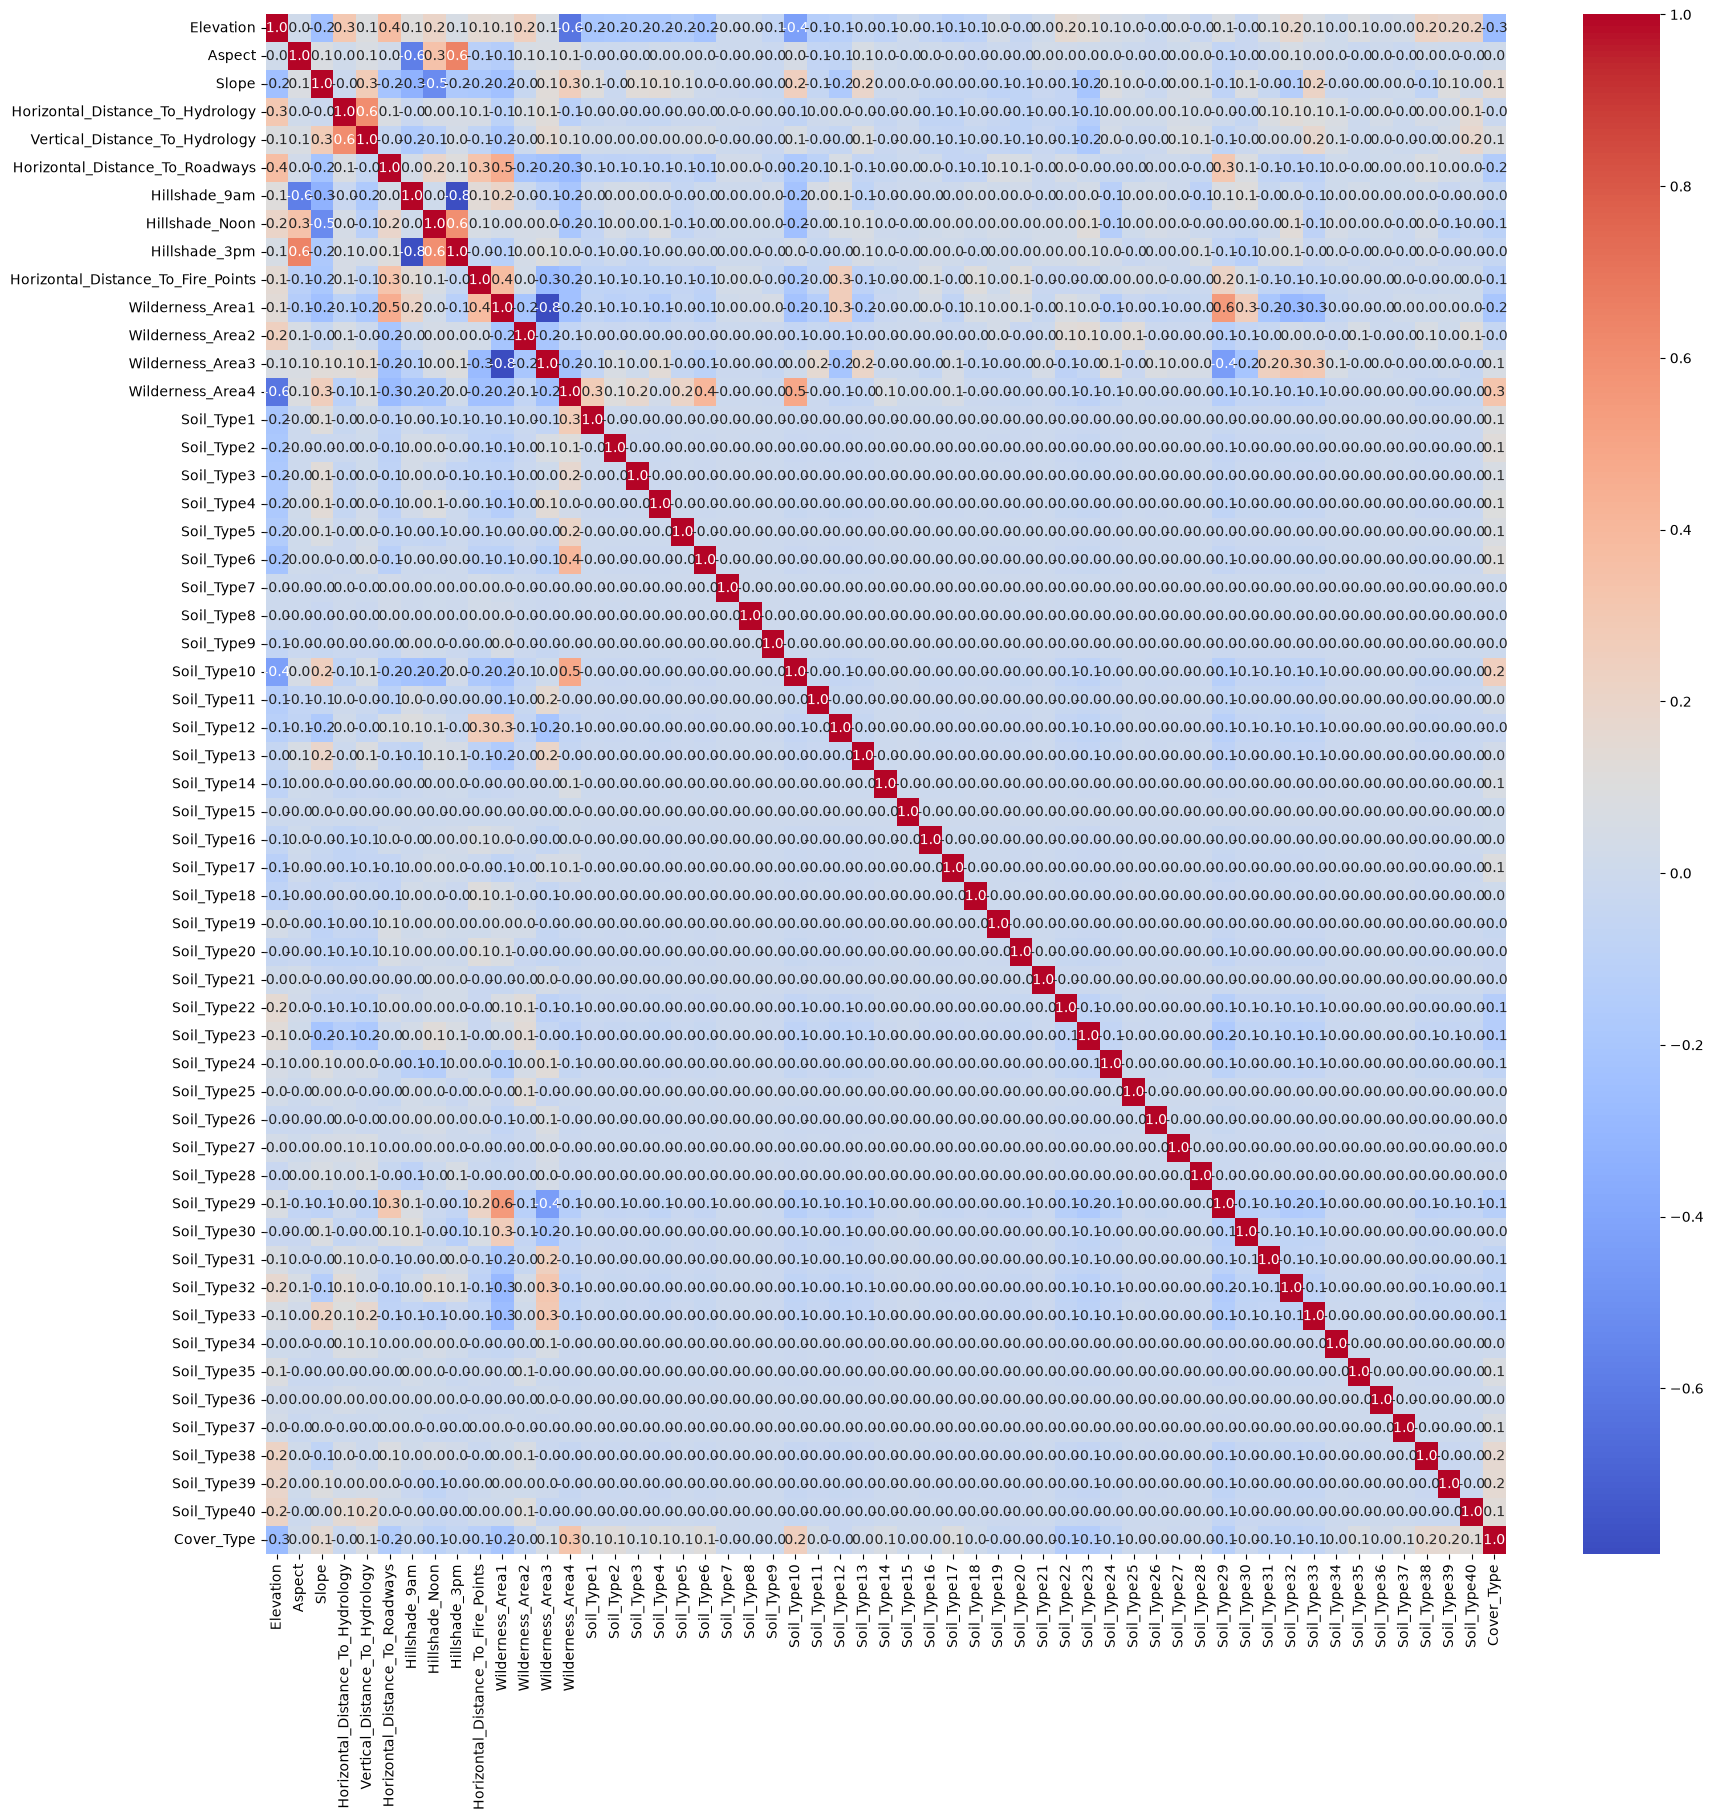

In [16]:
plt.figure(figsize=(20, 20))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".1f")
plt.show()

In [5]:
df.columns

Index(['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology',
       'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways',
       'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
       'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1',
       'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4',
       'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5',
       'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10',
       'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14',
       'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18',
       'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22',
       'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26',
       'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30',
       'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34',
       'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38',
       'Soil_Type39', 'Soil_Type40

Aspect, Hillshade_3pm, Hillshade_Noon, Horizontal_Distance_To_Hydrology, Vertical_Distance_To_Hydrology

In [34]:
X = df.drop('Cover_Type', axis=1)
y = df['Cover_Type']

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [40]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10
)

In [41]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [42]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy: ", accuracy)

Accuracy:  0.752373002418182


In [43]:
train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)

print("Train Accuracy :", train_score)
print("Test Accuracy  :", test_score)

Train Accuracy : 0.7550111981480565
Test Accuracy  : 0.752373002418182


In [44]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.74      0.74      0.74     42557
           2       0.75      0.83      0.79     56500
           3       0.74      0.85      0.79      7121
           4       0.91      0.40      0.56       526
           5       0.00      0.00      0.00      1995
           6       0.85      0.16      0.27      3489
           7       0.96      0.54      0.69      4015

    accuracy                           0.75    116203
   macro avg       0.71      0.50      0.55    116203
weighted avg       0.75      0.75      0.74    116203



c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [45]:
importance = model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                               Feature  Importance
0                            Elevation    0.368619
13                    Wilderness_Area4    0.105656
5      Horizontal_Distance_To_Roadways    0.056731
9   Horizontal_Distance_To_Fire_Points    0.043036
35                         Soil_Type22    0.032427
25                         Soil_Type12    0.031844
51                         Soil_Type38    0.030168
17                          Soil_Type4    0.027749
23                         Soil_Type10    0.027547
52                         Soil_Type39    0.023910
10                    Wilderness_Area1    0.020742
3     Horizontal_Distance_To_Hydrology    0.020675
36                         Soil_Type23    0.019592
12                    Wilderness_Area3    0.019580
15                          Soil_Type2    0.017331
7                       Hillshade_Noon    0.016483
4       Vertical_Distance_To_Hydrology    0.015789
1                               Aspect    0.015307
6                        Hillsh

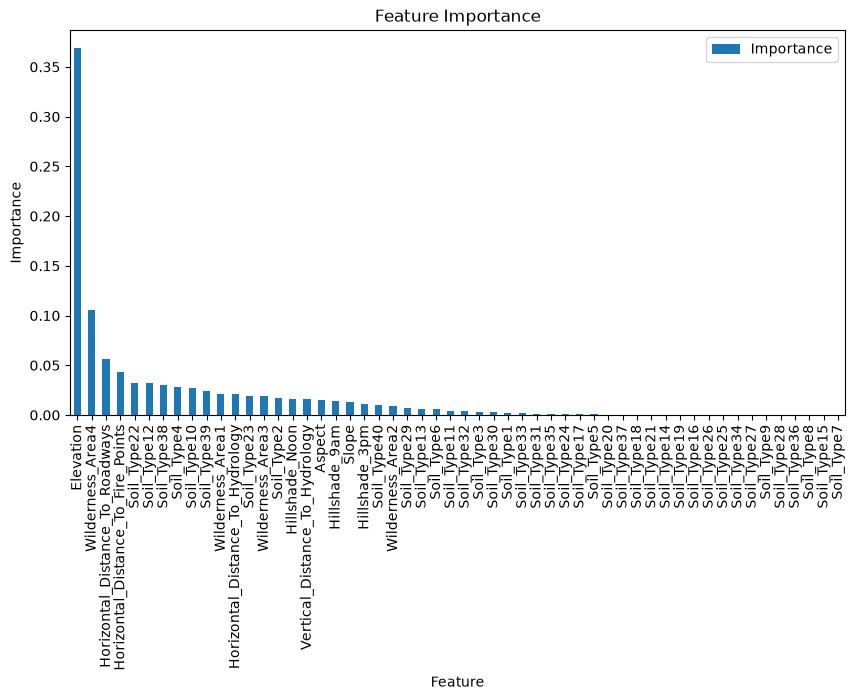

In [46]:
feature_importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    figsize=(10,5)
)

plt.title("Feature Importance")
plt.ylabel("Importance")
plt.xticks(rotation=90)

plt.show()